# 01 — Exploratory Data Analysis (EDA)

**Kelompok 12 · Kelas B2 · Prediksi Customer Churn Telco**

Notebook ini memeriksa dataset IBM Telco Customer Churn sebelum pemodelan: arti kolom, nilai kosong,
duplikat, outlier, dan pola churn pada data latih. Semua tabel dan grafik disimpan ke folder
`docs/eda(explaratory data analysis)/` dan ditampilkan kembali pada tab **EDA & Dokumentasi** di aplikasi.

Jalankan dari folder utama repository, urut dari sel pertama sampai terakhir.

## 1. Import library

`pandas` dan `numpy` untuk mengolah data, `matplotlib` untuk grafik, dan `train_test_split` untuk membagi
data latih dan uji. `BASE` diambil dari `training_data.py` supaya lokasi file sama dengan aplikasi.

In [1]:
import json

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

from training_data import BASE

## 2. Lokasi output dan warna grafik

Hasil EDA disimpan di `OUT`. Warna grafik disamakan dengan tampilan aplikasi; `DIVERGING` dipakai untuk
peta warna korelasi (negatif cokelat, positif biru).

In [2]:
OUT = BASE / "docs" / "eda(explaratory data analysis)"
OUT.mkdir(parents=True, exist_ok=True)
DATASET_URL = "https://www.kaggle.com/datasets/blastchar/telco-customer-churn"

INK = "#16181A"
ACCENT = "#1F4FD8"
ACCENT_SOFT = "#E4EAFB"
SIGNAL = "#96590C"
SIGNAL_SOFT = "#F4E8D2"
RECESSIVE = "#9C988D"
RULE = "#C9C4B8"
PAPER = "#F7F6F2"
DIVERGING = matplotlib.colors.LinearSegmentedColormap.from_list(
    "lembar", [SIGNAL, "#C9A05A", PAPER, "#9DB6F2", ACCENT])

## 3. Arti setiap kolom

Penjelasan singkat 21 kolom dataset. Teks ini dipakai untuk menyusun kamus variabel.

In [3]:
MEANINGS = {
    "customerID": "Identitas unik pelanggan; tidak digunakan model.",
    "gender": "Jenis kelamin pelanggan (Female/Male).",
    "SeniorCitizen": "Indikator pelanggan senior: 1=ya, 0=tidak.",
    "Partner": "Apakah pelanggan memiliki pasangan (Yes/No).",
    "Dependents": "Apakah pelanggan memiliki tanggungan (Yes/No).",
    "tenure": "Lama berlangganan, dalam bulan.",
    "PhoneService": "Apakah pelanggan memakai layanan telepon (Yes/No).",
    "MultipleLines": "Layanan beberapa jalur telepon; No phone service jika tanpa telepon.",
    "InternetService": "Jenis internet: DSL, Fiber optic, atau No.",
    "OnlineSecurity": "Layanan keamanan online; No internet service jika tanpa internet.",
    "OnlineBackup": "Layanan backup online; No internet service jika tanpa internet.",
    "DeviceProtection": "Layanan perlindungan perangkat; No internet service jika tanpa internet.",
    "TechSupport": "Layanan bantuan teknis; No internet service jika tanpa internet.",
    "StreamingTV": "Layanan streaming TV; No internet service jika tanpa internet.",
    "StreamingMovies": "Layanan streaming film; No internet service jika tanpa internet.",
    "Contract": "Durasi kontrak: Month-to-month, One year, Two year.",
    "PaperlessBilling": "Penggunaan tagihan tanpa kertas (Yes/No).",
    "PaymentMethod": "Metode pembayaran: cek elektronik/pos atau transfer/kartu otomatis.",
    "MonthlyCharges": "Tagihan bulanan pelanggan, dalam dolar.",
    "TotalCharges": "Total tagihan selama berlangganan; tidak digunakan model aplikasi.",
    "Churn": "Target: Yes=berhenti berlangganan, No=tidak berhenti dalam periode label dataset.",
}

## 4. Fungsi bantu tabel Markdown

`md_table` mengubah DataFrame menjadi tabel Markdown untuk laporan `EDA.md`.

In [4]:
def md_table(frame):
    headers = list(frame.columns)
    lines = ["| " + " | ".join(map(str, headers)) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    for row in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(str(v).replace("|", "/") for v in row) + " |")
    return "\n".join(lines)

## 5. Memuat dan membersihkan data

`TotalCharges` tersimpan sebagai teks. Setelah diubah menjadi angka, 11 nilai kosong terlihat (semuanya
pelanggan dengan `tenure = 0`). Baris tersebut dihapus sehingga data bersih berisi 7.032 pelanggan.

In [5]:
raw = pd.read_csv(BASE / "Telco-Customer-Churn.csv")
numeric = raw.copy()
numeric["TotalCharges"] = pd.to_numeric(numeric["TotalCharges"], errors="coerce")
complete = numeric.dropna().reset_index(drop=True)

print(f"Data awal       : {raw.shape[0]:,} baris, {raw.shape[1]} kolom")
print(f"TotalCharges kosong setelah konversi: {numeric['TotalCharges'].isna().sum()}")
print(f"Data bersih     : {complete.shape[0]:,} baris")
display(raw.head())

Data awal       : 7,043 baris, 21 kolom
TotalCharges kosong setelah konversi: 11
Data bersih     : 7,032 baris


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 6. Membagi data latih dan uji

Pembagian 80:20 secara stratified dengan `random_state=42`, sama dengan pembagian saat melatih model.
Hubungan fitur dengan churn hanya dianalisis pada data latih agar data uji tetap murni untuk evaluasi akhir.
`features` berisi 18 fitur input model (tanpa `customerID`, `TotalCharges`, dan `Churn`).

In [6]:
y = complete["Churn"].eq("Yes").astype(int)
train_idx, test_idx = train_test_split(np.arange(len(complete)), test_size=0.2,
                                       stratify=y, random_state=42)
train = complete.iloc[train_idx].copy()
test = complete.iloc[test_idx].copy()
features = complete.drop(columns=["customerID", "TotalCharges", "Churn"])

print(f"Data latih: {len(train):,} | Data uji: {len(test):,} | Fitur input: {features.shape[1]}")

Data latih: 5,625 | Data uji: 1,407 | Fitur input: 18


## 7. Kamus variabel

Tipe data, jumlah nilai unik, arti, dan peran setiap kolom (fitur, target, atau dihapus).

In [7]:
dictionary = pd.DataFrame([{
    "Variabel": col, "Tipe CSV": str(raw[col].dtype),
    "Tipe semantik": "target biner" if col == "Churn" else
    ("numerik kontinu" if col in ["MonthlyCharges", "TotalCharges"] else
     "numerik diskrit" if col == "tenure" else "ID" if col == "customerID" else "kategorikal"),
    "Jumlah nilai unik": int(numeric[col].nunique()), "Arti": MEANINGS[col],
    "Peran": "target" if col == "Churn" else "dihapus" if col in ["customerID", "TotalCharges"] else "fitur",
} for col in raw.columns])
dictionary.to_csv(OUT / "data_dictionary.csv", index=False, encoding="utf-8-sig")
display(dictionary)

,Variabel,Tipe CSV,Tipe semantik,Jumlah nilai unik,Arti,Peran
0,customerID,str,ID,7043,Identitas unik pelanggan; tidak digunakan model.,dihapus
1,gender,str,kategorikal,2,Jenis kelamin pelanggan (Female/Male).,fitur
2,SeniorCitizen,int64,kategorikal,2,"Indikator pelanggan senior: 1=ya, 0=tidak.",fitur
3,Partner,str,kategorikal,2,Apakah pelanggan memiliki pasangan (Yes/No).,fitur
4,Dependents,str,kategorikal,2,Apakah pelanggan memiliki tanggungan (Yes/No).,fitur
5,tenure,int64,numerik diskrit,73,"Lama berlangganan, dalam bulan.",fitur
6,PhoneService,str,kategorikal,2,Apakah pelanggan memakai layanan telepon (Yes/...,fitur
7,MultipleLines,str,kategorikal,3,Layanan beberapa jalur telepon; No phone servi...,fitur
8,InternetService,str,kategorikal,3,"Jenis internet: DSL, Fiber optic, atau No.",fitur
9,OnlineSecurity,str,kategorikal,3,Layanan keamanan online; No internet service j...,fitur


## 8. Statistik deskriptif

Ringkasan statistik semua kolom disimpan ke `descriptive_statistics.csv`; tabel di bawah menampilkan tiga
kolom angka utama.

In [8]:
numeric.describe(include="all").T.to_csv(OUT / "descriptive_statistics.csv")
display(numeric[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(3))

,tenure,MonthlyCharges,TotalCharges
count,7043.000,7043.000,7032.000
mean,32.371,64.762,2283.300
std,24.559,30.090,2266.771
min,0.000,18.250,18.800
25%,9.000,35.500,401.450
50%,29.000,70.350,1397.475
75%,55.000,89.850,3794.738
max,72.000,118.750,8684.800


## 9. Nilai kosong (missing value)

Jumlah sel kosong pada tiga tahap: CSV awal, setelah `TotalCharges` diubah menjadi angka, dan setelah data
dibersihkan.

In [9]:
missing = pd.DataFrame({"Kolom": raw.columns,
                        "Kosong pada CSV awal": raw.isna().sum().values,
                        "Kosong setelah konversi angka": numeric.isna().sum().values,
                        "Kosong setelah data dibersihkan": complete.isna().sum().values})
missing.to_csv(OUT / "missing_values.csv", index=False)
display(missing[missing.iloc[:, 1:].sum(axis=1) > 0])

,Kolom,Kosong pada CSV awal,Kosong setelah konversi angka,Kosong setelah data dibersihkan
19,TotalCharges,0,11,0


## 10. Outlier dengan aturan IQR

Nilai dianggap outlier bila berada di bawah Q1 − 1,5×IQR atau di atas Q3 + 1,5×IQR, dengan IQR = Q3 − Q1.

In [10]:
outliers = []
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    values = numeric[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    outliers.append({"Variabel": col, "Minimum": float(values.min()), "Maximum": float(values.max()),
                     "Batas IQR bawah": round(float(low), 4), "Batas IQR atas": round(float(high), 4),
                     "Jumlah outlier IQR": int(((values < low) | (values > high)).sum())})
outliers_df = pd.DataFrame(outliers)
outliers_df.to_csv(OUT / "outliers_iqr.csv", index=False)
display(outliers_df)

,Variabel,Minimum,Maximum,Batas IQR bawah,Batas IQR atas,Jumlah outlier IQR
0,tenure,0.00,72.00,-60.0000,124.0000,0
1,MonthlyCharges,18.25,118.75,-46.0250,171.3750,0
2,TotalCharges,18.80,8684.80,-4688.4813,8884.6688,0


## 11. Pemeriksaan duplikat

Duplikat dihitung pada beberapa tingkat: baris mentah, `customerID`, baris tanpa ID, profil fitur setelah
dibersihkan, dan profil data uji yang sama persis dengan profil di data latih.

In [11]:
duplicate_counts = {
    "raw_full_rows": int(raw.duplicated().sum()),
    "customerID": int(raw["customerID"].duplicated().sum()),
    "raw_without_id": int(raw.drop(columns="customerID").duplicated().sum()),
    "clean_without_id_total_including_target": int(complete.drop(columns=["customerID", "TotalCharges"]).duplicated().sum()),
    "clean_features_only": int(features.duplicated().sum()),
    "test_features_matching_train": len(features.iloc[test_idx].merge(
        features.iloc[train_idx].drop_duplicates(), on=list(features.columns), how="inner")),
}
display(pd.Series(duplicate_counts, name="Jumlah").to_frame())

,Jumlah
raw_full_rows,0
customerID,0
raw_without_id,22
clean_without_id_total_including_target,27
clean_features_only,48
test_features_matching_train,18


## 12. Persentase churn per kategori (data latih)

Untuk setiap fitur kategori dihitung jumlah pelanggan, jumlah churn, dan persentase churn. Tabel di bawah
menampilkan 10 kategori dengan persentase churn tertinggi.

In [12]:
rates = []
for col in features.columns:
    if col in ["tenure", "MonthlyCharges"]:
        continue
    for value, group in train.groupby(col):
        rates.append({"Fitur": col, "Kategori": str(value), "Jumlah train": len(group),
                      "Churn train": int(group["Churn"].eq("Yes").sum()),
                      "Churn rate train": round(float(group["Churn"].eq("Yes").mean()), 4)})
rates_df = pd.DataFrame(rates)
rates_df.to_csv(OUT / "categorical_churn_rates_train.csv", index=False)
display(rates_df.sort_values("Churn rate train", ascending=False).head(10))

,Fitur,Kategori,Jumlah train,Churn train,Churn rate train
41,PaymentMethod,Electronic check,1907,866,0.4541
34,Contract,Month-to-month,3085,1329,0.4308
16,OnlineSecurity,No,2803,1174,0.4188
14,InternetService,Fiber optic,2483,1038,0.4180
3,SeniorCitizen,1,910,380,0.4176
25,TechSupport,No,2759,1152,0.4175
19,OnlineBackup,No,2446,984,0.4023
22,DeviceProtection,No,2473,965,0.3902
38,PaperlessBilling,Yes,3349,1120,0.3344
31,StreamingMovies,No,2222,743,0.3344


## 13. Korelasi fitur angka (data latih)

Korelasi Pearson antara empat kolom angka. Nilai `TotalCharges` dengan `tenure` yang tinggi menjadi salah
satu alasan `TotalCharges` tidak dipakai sebagai fitur.

In [13]:
correlations = train[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].corr()
correlations.to_csv(OUT / "correlations_train.csv")
display(correlations.round(3))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.014,0.214,0.097
tenure,0.014,1.000,0.250,0.827
MonthlyCharges,0.214,0.250,1.000,0.653
TotalCharges,0.097,0.827,0.653,1.000


## 14. Pengaturan grafik

Gaya grafik disamakan untuk semua gambar. Fungsi `save` menyimpan grafik ke folder EDA (160 dpi), mencatat
interpretasinya untuk laporan, lalu mencetak interpretasi tersebut di bawah grafik.

In [14]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": RULE, "axes.labelcolor": INK,
                     "xtick.color": "#6B6A64", "ytick.color": "#6B6A64",
                     "axes.titlecolor": INK,
                     "figure.facecolor": "white", "axes.facecolor": "white"})
figure_notes = []


def save(fig, name, caption):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=160, bbox_inches="tight")
    figure_notes.append({"file": name, "interpretation": caption})
    print(caption)

## 15. Grafik 1 — Sebaran target churn

Jumlah pelanggan churn dan tidak churn pada data awal, data bersih, dan data latih.

Setelah data dibersihkan, sekitar 73,4% pelanggan tidak churn dan 26,6% churn. Jumlah kedua kelompok tidak seimbang. Karena itu, akurasi perlu dilihat bersama precision, recall, dan F1 agar kemampuan mendeteksi churn tidak terlewat.


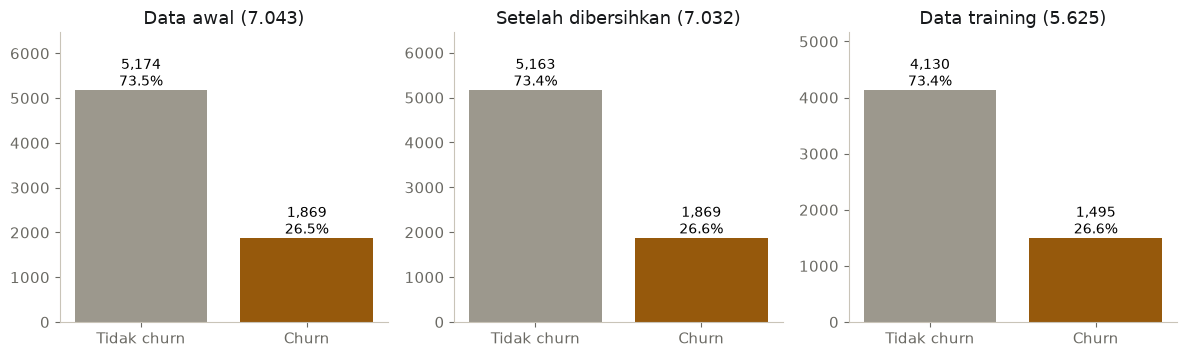

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, data, title in zip(axes, [raw, complete, train],
                           ["Data awal (7.043)", "Setelah dibersihkan (7.032)", "Data training (5.625)"]):
    counts = data["Churn"].value_counts().reindex(["No", "Yes"])
    ax.bar(["Tidak churn", "Churn"], counts, color=[RECESSIVE, SIGNAL])
    ax.set_title(title)
    for i, count in enumerate(counts):
        ax.text(i, count, f"{count:,}\n{count / len(data):.1%}", ha="center", va="bottom", fontsize=10)
    ax.set_ylim(0, counts.max() * 1.25)
save(fig, "01_target_distribution.png", "Setelah data dibersihkan, sekitar 73,4% pelanggan tidak churn dan "
     "26,6% churn. Jumlah kedua kelompok tidak seimbang. Karena itu, akurasi perlu dilihat bersama "
     "precision, recall, dan F1 agar kemampuan mendeteksi churn tidak terlewat.")

## 16. Grafik 2 — Histogram fitur angka

Sebaran `tenure`, `MonthlyCharges`, dan `TotalCharges` pada data latih.

Tenure menunjukkan lama berlangganan, dari pelanggan baru hingga 72 bulan. Tagihan bulanan tersebar dalam beberapa kelompok, sedangkan total tagihan banyak berada pada nilai rendah. StandardScaler menyamakan skala fitur angka untuk Logistic Regression, bukan membuat distribusinya menjadi normal.


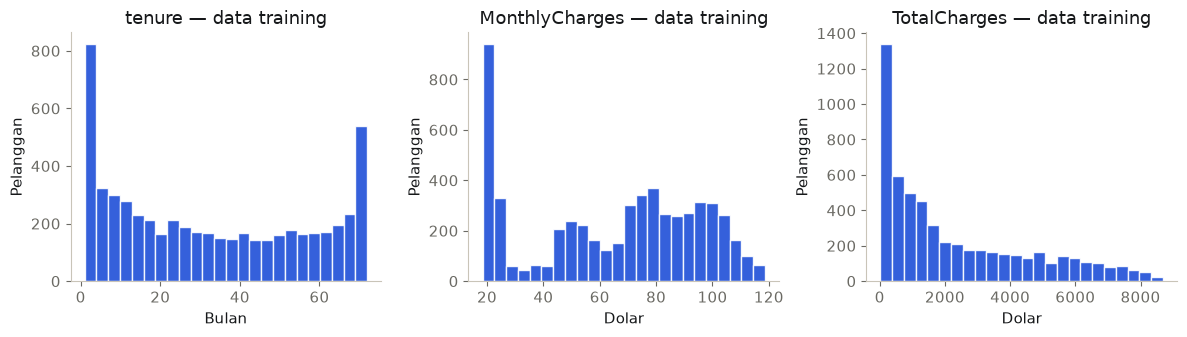

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    ax.hist(train[col], bins=24, color=ACCENT, alpha=0.9, edgecolor="white")
    ax.set_title(col + " — data training")
    ax.set_ylabel("Pelanggan")
    ax.set_xlabel("Bulan" if col == "tenure" else "Dolar")
save(fig, "02_numeric_histograms_train.png", "Tenure menunjukkan lama berlangganan, dari pelanggan baru "
     "hingga 72 bulan. Tagihan bulanan tersebar dalam beberapa kelompok, sedangkan total tagihan "
     "banyak berada pada nilai rendah. StandardScaler menyamakan skala fitur angka untuk Logistic "
     "Regression, bukan membuat distribusinya menjadi normal.")

## 17. Grafik 3 — Boxplot fitur angka per status churn

Perbandingan nilai tengah dan sebaran fitur angka antara pelanggan churn dan tidak churn. Median
`tenure` dan `MonthlyCharges` per kelompok juga disimpan untuk ringkasan.

Pada data training, median lama berlangganan pelanggan churn adalah 10 bulan, sedangkan pelanggan tidak churn 38 bulan. Median tagihannya masing-masing $79.90 dan $64.68. Pola ini belum membuktikan sebab-akibat. Titik outlier pada boxplot dihitung per kelompok, berbeda dari tabel IQR yang memeriksa seluruh data sekaligus.


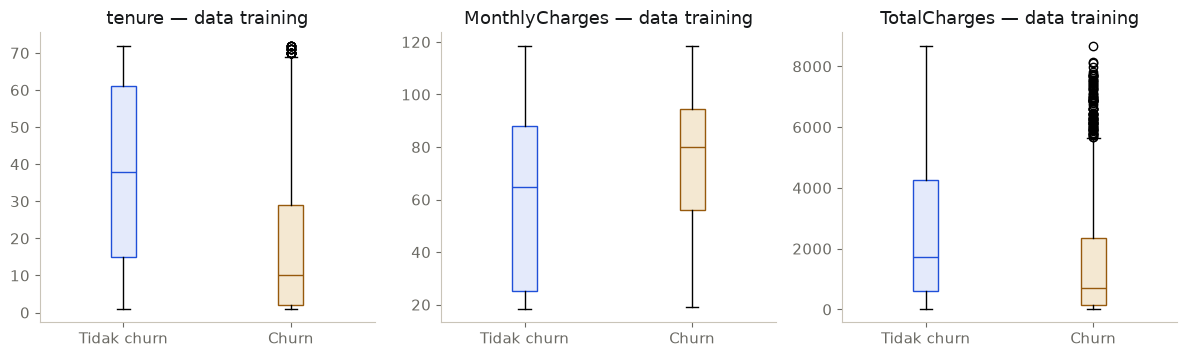

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    groups = [train.loc[train.Churn == label, col] for label in ["No", "Yes"]]
    boxes = ax.boxplot(groups, tick_labels=["Tidak churn", "Churn"], patch_artist=True,
                       boxprops={"facecolor": ACCENT_SOFT}, medianprops={"color": ACCENT})
    for patch, fill, edge in zip(boxes["boxes"], [ACCENT_SOFT, SIGNAL_SOFT],
                                 [ACCENT, SIGNAL]):
        patch.set_facecolor(fill)
        patch.set_edgecolor(edge)
    for median, edge in zip(boxes["medians"], [ACCENT, SIGNAL]):
        median.set_color(edge)
    ax.set_title(col + " — data training")
medians = train.groupby("Churn")[["tenure", "MonthlyCharges"]].median()
save(fig, "03_numeric_boxplots_train.png", f"Pada data training, median lama berlangganan pelanggan "
     f"churn adalah {medians.loc['Yes', 'tenure']:.0f} bulan, sedangkan pelanggan tidak churn "
     f"{medians.loc['No', 'tenure']:.0f} bulan. Median tagihannya masing-masing "
     f"${medians.loc['Yes', 'MonthlyCharges']:.2f} dan ${medians.loc['No', 'MonthlyCharges']:.2f}. "
     "Pola ini belum membuktikan sebab-akibat. Titik outlier pada boxplot dihitung per kelompok, "
     "berbeda dari tabel IQR yang memeriksa seluruh data sekaligus.")

## 18. Grafik 4 — Peta korelasi

Visualisasi tabel korelasi dari langkah 13.

Korelasi total tagihan (TotalCharges) dan lama berlangganan (tenure) adalah 0.827 pada data training. Keduanya berkaitan, tetapi tidak selalu bisa saling menggantikan. TotalCharges tidak diminta di aplikasi agar pengisian lebih mudah. Hasil model dengan dan tanpa fitur ini belum dibandingkan.


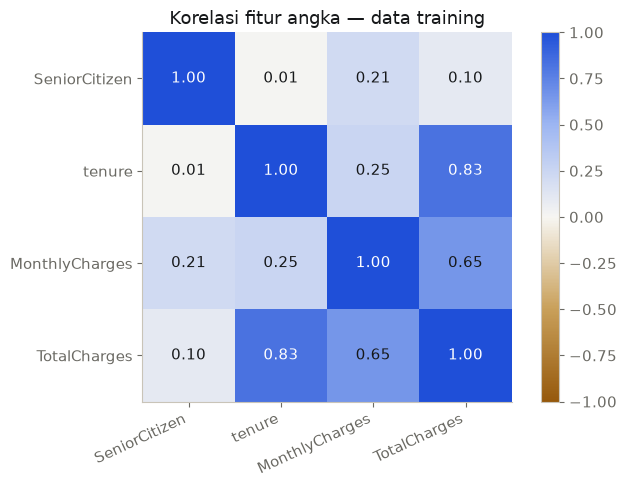

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(correlations, vmin=-1, vmax=1, cmap=DIVERGING)
ax.set_xticks(range(4), correlations.columns, rotation=25, ha="right")
ax.set_yticks(range(4), correlations.index)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{correlations.iloc[i,j]:.2f}", ha="center", va="center",
                color="white" if abs(correlations.iloc[i,j]) > 0.7 else INK)
fig.colorbar(im, ax=ax)
ax.set_title("Korelasi fitur angka — data training")
save(fig, "04_correlation_train.png", f"Korelasi total tagihan (TotalCharges) dan lama berlangganan "
     f"(tenure) adalah {correlations.loc['TotalCharges','tenure']:.3f} pada data training. "
     "Keduanya berkaitan, tetapi tidak selalu bisa saling menggantikan. TotalCharges tidak "
     "diminta di aplikasi agar pengisian lebih mudah. Hasil model dengan dan tanpa fitur ini belum dibandingkan.")

## 19. Grafik 5 — Persentase churn per kategori

Persentase churn menurut jenis kontrak, layanan internet, dan metode pembayaran.

Pada data training, 43.1% pelanggan kontrak bulanan churn, dibanding 2.9% pada kontrak dua tahun. Persentase churn juga berbeda menurut layanan internet dan cara pembayaran. Ini membantu mengenali pola pelanggan, tetapi belum membuktikan bahwa mengganti kontrak atau metode pembayaran akan mencegah churn.


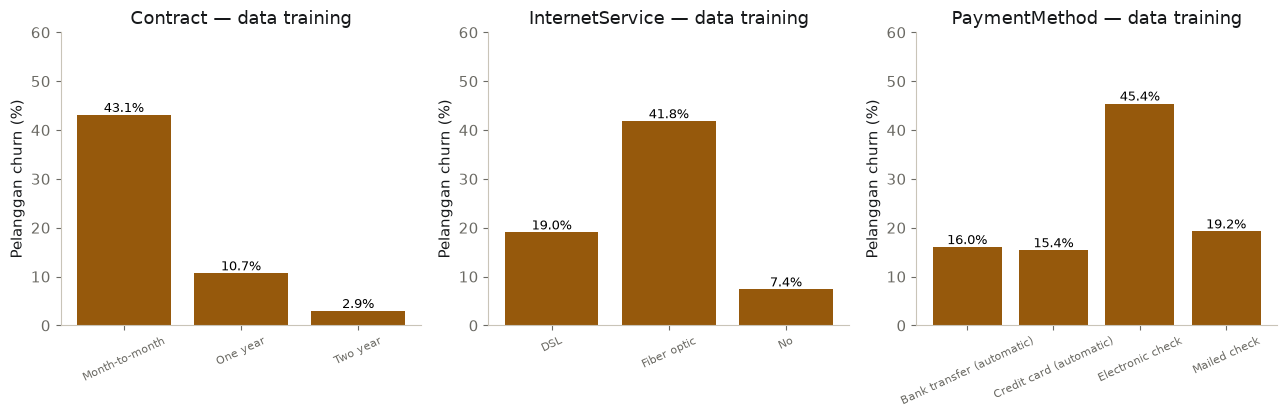

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    subset = rates_df[rates_df.Fitur == col]
    ax.bar(subset.Kategori, subset["Churn rate train"] * 100, color=SIGNAL)
    ax.set_title(col + " — data training")
    ax.set_ylabel("Pelanggan churn (%)")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    for i, value in enumerate(subset["Churn rate train"]):
        ax.text(i, value * 100, f"{value:.1%}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 60)
month = rates_df[(rates_df.Fitur == "Contract") & (rates_df.Kategori == "Month-to-month")].iloc[0]
two = rates_df[(rates_df.Fitur == "Contract") & (rates_df.Kategori == "Two year")].iloc[0]
save(fig, "05_categorical_churn_train.png", f"Pada data training, {month['Churn rate train']:.1%} "
     f"pelanggan kontrak bulanan churn, dibanding {two['Churn rate train']:.1%} pada kontrak dua tahun. "
     "Persentase churn juga berbeda menurut layanan internet dan cara pembayaran. Ini membantu "
     "mengenali pola pelanggan, tetapi belum membuktikan bahwa mengganti kontrak atau metode pembayaran akan mencegah churn.")

## 20. Grafik 6 — Sebaran fitur kategori

Jumlah pelanggan per jenis kontrak, layanan internet, dan status senior.

Sebagian besar pelanggan bukan senior. Jumlah pelanggan juga berbeda di setiap jenis kontrak dan layanan internet. Saat membandingkan persentase churn, perhatikan jumlah pelanggan dalam kelompoknya: hasil kelompok kecil belum tentu mewakili semua pelanggan.


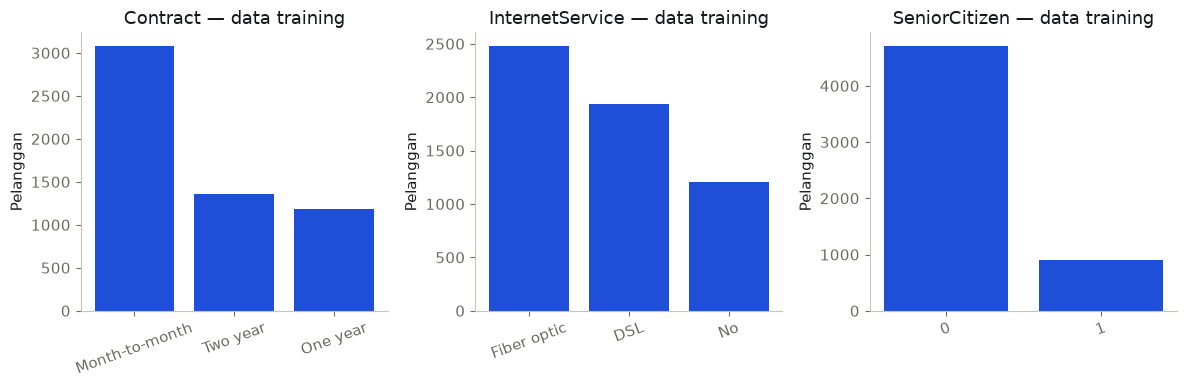

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "SeniorCitizen"]):
    counts = train[col].astype(str).value_counts()
    ax.bar(counts.index, counts.values, color=ACCENT)
    ax.set_title(col + " — data training")
    ax.set_ylabel("Pelanggan")
    ax.tick_params(axis="x", rotation=20)
save(fig, "06_categorical_distribution_train.png", "Sebagian besar pelanggan bukan senior. Jumlah "
     "pelanggan juga berbeda di setiap jenis kontrak dan layanan internet. Saat membandingkan "
     "persentase churn, perhatikan jumlah pelanggan dalam kelompoknya: hasil kelompok kecil belum tentu mewakili semua pelanggan.")

## 21. Grafik 7 — Lama berlangganan dan tagihan bulanan

Scatter plot paling banyak 500 pelanggan per kelompok churn agar titiknya mudah dibaca.

Pelanggan churn dan tidak churn tersebar pada lama berlangganan dan tagihan yang mirip. Dua fitur ini saja belum dapat memisahkan semua pelanggan dengan jelas. Grafik mengambil paling banyak 500 pelanggan per kelompok agar mudah dibaca; jumlah titiknya bukan perbandingan jumlah kelas.


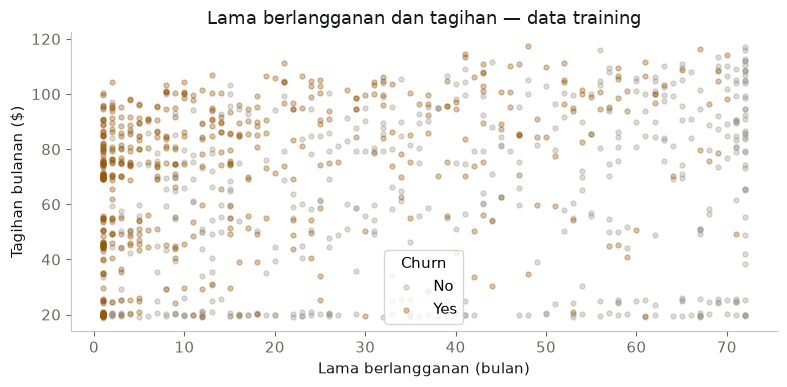

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, color in [("No", RECESSIVE), ("Yes", SIGNAL)]:
    sample = train[train.Churn == label].sample(n=min(500, int((train.Churn == label).sum())), random_state=42)
    ax.scatter(sample.tenure, sample.MonthlyCharges, s=13, alpha=0.35, color=color, label=label)
ax.set(xlabel="Lama berlangganan (bulan)", ylabel="Tagihan bulanan ($)",
       title="Lama berlangganan dan tagihan — data training")
ax.legend(title="Churn")
save(fig, "07_scatter_train.png", "Pelanggan churn dan tidak churn tersebar pada lama berlangganan "
     "dan tagihan yang mirip. Dua fitur ini saja belum dapat memisahkan semua pelanggan dengan jelas. "
     "Grafik mengambil paling banyak 500 pelanggan per kelompok agar mudah dibaca; jumlah titiknya bukan perbandingan jumlah kelas.")

## 22. Ringkasan `summary.json`

Angka utama EDA dan daftar grafik beserta interpretasinya. Aplikasi membaca file ini untuk menampilkan
galeri grafik pada tab EDA.

In [22]:
summary = {
    "source": DATASET_URL, "raw_rows": len(raw), "raw_columns": raw.shape[1],
    "clean_rows": len(complete), "input_features": features.shape[1],
    "n_train": len(train), "n_test": len(test), "missing_totalcharges": int(numeric.TotalCharges.isna().sum()),
    "dropped_rows_tenure_zero": int(numeric.loc[numeric.TotalCharges.isna(), "tenure"].eq(0).sum()),
    "target_clean": {k: int(v) for k, v in complete.Churn.value_counts().items()},
    "duplicates": duplicate_counts, "outliers": outliers, "figures": figure_notes,
    "associations_on": "train-only", "numeric_medians_train": medians.round(2).to_dict(),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"summary.json disimpan: {len(figure_notes)} grafik tercatat")

summary.json disimpan: 7 grafik tercatat


## 23. Laporan `EDA.md`

Menggabungkan semua tabel, grafik, dan interpretasi menjadi satu laporan Markdown.

In [23]:
sections = ["# Exploratory Data Analysis — Telco Churn", "\nKelompok 12 • Kelas B2",
            f"\nSumber: {DATASET_URL}",
            "\n## 1. Informasi dataset",
            f"Data awal: **{len(raw):,} pelanggan, {raw.shape[1]} kolom**. Setelah dibersihkan: **{len(complete):,} pelanggan, "
            f"18 fitur + 1 target**. customerID adalah ID; Churn Yes=1, No=0. "
            "Grafik hubungan fitur–target memakai train saja (5.625); test (1.407) disimpan untuk evaluasi akhir. "
            "Pemeriksaan kualitas data mentah tidak melakukan fitting preprocessing.",
            "\n## 2. Kamus variabel", md_table(dictionary),
            "\n## 3. Statistik deskriptif", md_table(numeric[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(3).reset_index()),
            "\n## 4. Missing value", md_table(missing),
            "Sebelas string kosong pada TotalCharges terdeteksi setelah konversi numerik. "
            "Seluruhnya tenure=0 dan Churn=No. Data pemodelan awal dipertahankan untuk perbandingan eksperimen; "
            "karena fitur TotalCharges akhirnya dihapus, membuang baris ini bukan keharusan model. "
            "Eksklusi pelanggan baru merupakan keterbatasan yang perlu diuji pada pengembangan berikutnya.",
            "\n## 5. Duplikat", md_table(pd.DataFrame(duplicate_counts.items(), columns=["Pemeriksaan", "Jumlah"])),
            "Tidak ada ID ganda atau baris mentah identik. Setelah fitur identitas/kumulatif dihapus, "
            "sebagian profil menjadi sama. ID berbeda dapat mewakili pelanggan berbeda, sehingga tidak dihapus otomatis. "
            "Ada profil test identik dengan train; ini membatasi klaim generalisasi untuk profil yang benar-benar baru. "
            "Pengembangan: evaluasi group-aware berdasarkan profil untuk mengukur sensitivitas hasil.",
            "\n## 6. Outlier", md_table(outliers_df),
            "Tidak ada outlier dengan aturan 1,5×IQR pada tiga fitur numerik. Ini tidak berarti semua catatan "
            "bebas anomali domain. Tidak dilakukan clipping/penghapusan outlier; nilai layanan sah dipertahankan.",
            "\n## 7. Visualisasi dan interpretasi"]
for figure in figure_notes:
    sections.extend([f"\n### {figure['file']}", f"![{figure['file']}]({figure['file']})", figure["interpretation"]])
sections.extend(["\n## 8. Implikasi preprocessing",
                 "- StandardScaler pada SeniorCitizen (indikator biner), tenure, MonthlyCharges; "
                 "OneHotEncoder pada 15 fitur kategorikal. Scaling indikator biner valid secara matematis, "
                 "namun semantiknya tetap kategori; scaling tidak diperlukan pohon, dipakai untuk pipeline konsisten.",
                 "- Fit scaler/encoder hanya pada training fold melalui Pipeline; tidak memakai statistik test.",
                 "- Class weight diuji dalam GridSearch; tidak memakai SMOTE pada eksperimen ini.",
                 "- TotalCharges dihapus untuk input sederhana; tidak mengklaim koefisien negatif adalah kesalahan.",
                 "- Tabel lengkap churn rate semua kategori tersedia di categorical_churn_rates_train.csv."])
(OUT / "EDA.md").write_text("\n\n".join(sections) + "\n", encoding="utf-8")
print(f"EDA: {len(raw)} raw -> {len(complete)} clean; {len(figure_notes)} grafik -> {OUT}")

EDA: 7043 raw -> 7032 clean; 7 grafik -> F:\apaelah\TUGAS\smt5\ML\projek ML\docs\eda(explaratory data analysis)
